In [ ]:
#Step 1 : Import required lib
import tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Convolution2D,MaxPooling2D,Flatten
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.layers import Dropout,BatchNormalization

In [ ]:
import shutil
import os

#Download the dataset from kaggle
import kagglehub
path = kagglehub.dataset_download("birajsth/cats-and-dogs-filtered")

#Destination directory
destination = "/content/Dataset"

#Create the destination directory if it doesn't exist
os.makedirs(destination, exist_ok=True)

#Copy all dataset files and folders
for item in os.listdir(path):
  source_item = os.path.join(path,item)
  destination_item = os.path.join(destination,item)

  if os.path.isdir(source_item):
    shutil.copytree(source_item,destination_item,dirs_exist_ok=True)

  else:
    shutil.copy2(source_item,destination_item)
print("Dataset saved successfully at:", destination)
print("Files:", os.listdir(destination))

100%|██████████| 131M/131M [00:07<00:00, 18.0MB/s]

Extracting files...


Dataset saved successfully at: /content/Dataset
Files: ['cats_and_dogs_filtered']


In [ ]:
#Create the pa1ath of datsets
PATH = "/content/Dataset/cats_and_dogs_filtered/cats_and_dogs_filtered"

In [ ]:
#Step 3 : Create the training and testing directory
train_dir = os.path.join(PATH,"train")
validation_dir = os.path.join(PATH,"validation")

In [ ]:
#Step 4: Create the cat and dog directory of training and validation
train_cat_dir = os.path.join(train_dir,"cats")
train_dog_dir = os.path.join(train_dir,"dogs")
validation_cat_dir = os.path.join(validation_dir,"cats")
validation_dog_dir = os.path.join(validation_dir,"dogs")

In [ ]:
from kagglehub.enum import T
#Step 5 : Check the length of training and validation cat and dog directory
num_cat_train = len(os.listdir(train_cat_dir))
num_dog_train = len(os.listdir(train_dog_dir))

num_cat_val = len(os.listdir(validation_cat_dir))
num_dog_val = len(os.listdir(validation_dog_dir))

total_train = num_cat_train + num_dog_train
total_val = num_cat_val + num_dog_val

In [ ]:
#print the length of all
print("total training cat images:", num_cat_train)
print("total training dog images:", num_dog_train)

print("total validation cat images:", num_cat_val)
print("total validation dog images:", num_dog_val)
print("--")
print("Total training images:", total_train)
print("Total validation images:", total_val)

total training cat images: 1000
total training dog images: 1000
total validation cat images: 500
total validation dog images: 500
--
Total training images: 2000
Total validation images: 1000


In [ ]:
#Step 6: Take hyperparameter
batch_size = 128
epochs = 10
IMG_HEIGHT = 150
IMG_WIDTH = 150

In [ ]:
#Step 7:  Generate the train images
train_img_gen = ImageDataGenerator(
    rescale = 1./255,
    rotation_range = 40,
    width_shift_range = 0.2,
    height_shift_range = 0.2,
    shear_range = 0.2,
    zoom_range = 0.2,
    horizontal_flip = True
)

validation_img_gen = ImageDataGenerator(rescale = 1./255)

In [ ]:
#Step 8 : Make the flow directory of training data

train_data_gen = train_img_gen.flow_from_directory(
    batch_size = batch_size,
    directory = train_dir,
    shuffle = True,
    target_size = (IMG_HEIGHT, IMG_WIDTH),
    class_mode = 'binary'
)

Found 2000 images belonging to 2 classes.


In [ ]:
#Step 9: Make the flow directory of validation data

val_data_gen = validation_img_gen.flow_from_directory(
    batch_size = batch_size,
    directory = validation_dir,
    target_size = (IMG_HEIGHT, IMG_WIDTH),
    class_mode = 'binary'
)

Found 1000 images belonging to 2 classes.


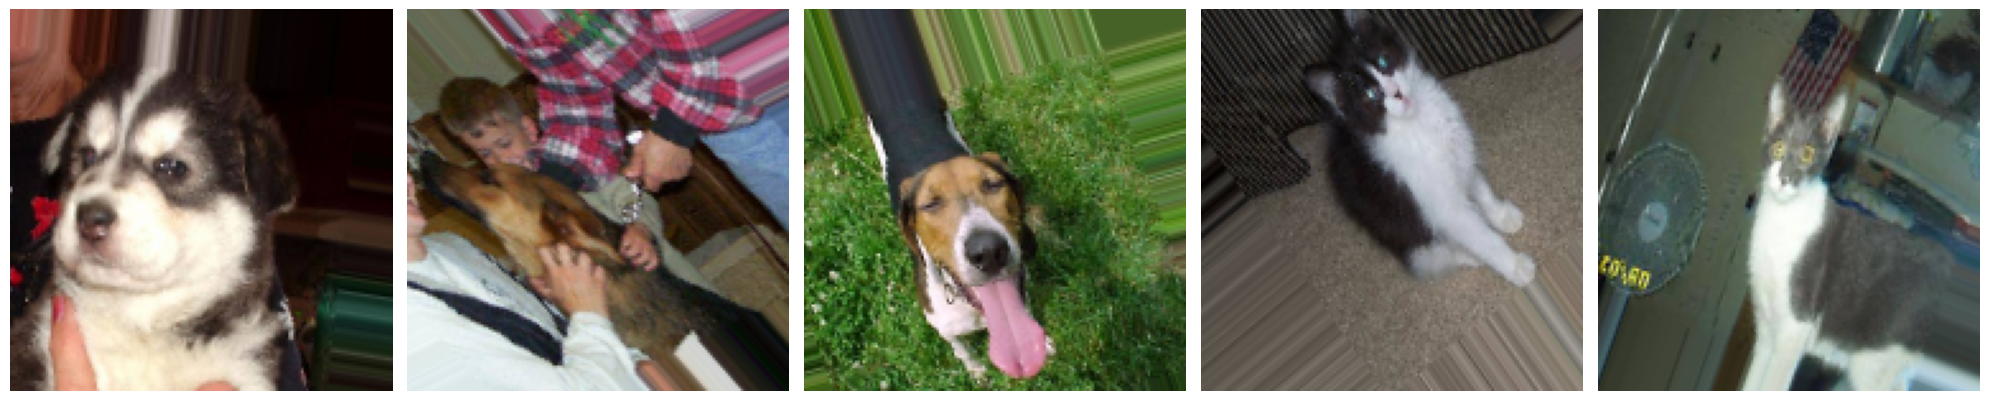

In [ ]:
#Show the five sample from train_data gen

sample_training_images, _ = next(train_data_gen)

#create the function to display five img

def plotImages(images_arr):
  fig, axes = plt.subplots(1,5,figsize=(20,20))
  axes = axes.flatten()
  for img,ax in zip(images_arr, axes):
    ax.imshow(img)
    ax.axis('off')
  plt.tight_layout()
  plt.show()

plotImages(sample_training_images[:5])

In [ ]:
#Step 10: Building model
model = Sequential()

model.add(Convolution2D(16,(3,3),padding='same',activation='relu',input_shape=(150,150,3)))
model.add(MaxPooling2D(2,2))
model.add(Dropout(0.2))
model.add(BatchNormalization())

model.add(Convolution2D(32,(3,3),padding='same',activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Dropout(0.2))
model.add(BatchNormalization())

model.add(Flatten())
model.add(Dense(512,activation='relu'))
model.add(Dropout(0.2))
model.add(BatchNormalization())
model.add(Dense(1,activation='sigmoid'))

In [ ]:
#Check the model summary
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 150, 150, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 75, 75, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 43808)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │    22,430,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,438,049 (85.59 MB)

 Trainable params: 22,436,929 (85.59 MB)

 Non-trainable params: 1,120 (4.38 KB)

In [ ]:
#Step 11: Model compile
model.compile(optimizer = Adam(learning_rate=0.001),
              loss=BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [ ]:
#Step 12: Train the model
history = model.fit(
    train_data_gen,
    steps_per_epoch=total_train // batch_size,
    epochs=epochs,
    validation_data=val_data_gen,
    validation_steps=total_val // batch_size
)


Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/nn.py:1286: UserWarning: "`binary_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Sigmoid activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


15/15 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.5780 - loss: 1.1576 - val_accuracy: 0.4955 - val_loss: 1.2604
Epoch 2/10
 1/15 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step - accuracy: 0.5312 - loss: 1.0448

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 134ms/step - accuracy: 0.5312 - loss: 1.0448 - val_accuracy: 0.5033 - val_loss: 1.2247
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.5796 - loss: 0.7900 - val_accuracy: 0.5011 - val_loss: 1.0344
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 147ms/step - accuracy: 0.5938 - loss: 0.7889 - val_accuracy: 0.5011 - val_loss: 1.0155
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.6095 - loss: 0.7179 - val_accuracy: 0.4978 - val_loss: 1.1217
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 142ms/step - accuracy: 0.6016 - loss: 0.7362 - val_accuracy: 0.4922 - val_loss: 1.1446
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.6208 - loss: 0.6822 - val_accuracy: 0.5011 - val_loss: 0.9456
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - accuracy: 0.6375 - loss: 0.6534 - val_accuracy: 0.4922 - val_loss: 0.9577
Epoch 9/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.6245 - loss: 0.6837 - val_accuracy: 0.4955 - val_loss: 1.

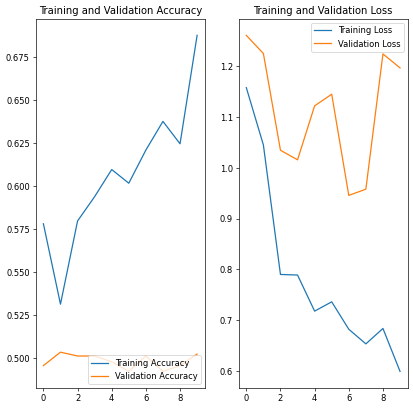

In [ ]:
#Make the training loss and validation loss plot
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(8,8),dpi=60)
plt.subplot(1,2,1)
plt.plot(epochs_range,acc,label='Training Accuracy')
plt.plot(epochs_range,val_acc,label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')


plt.subplot(1,2,2)
plt.plot(epochs_range,loss,label='Training Loss')
plt.plot(epochs_range,val_loss,label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()


In [ ]:
#Prediction on new img
from keras.models import load_model
import numpy as np
import cv2

img = cv2.imread(r"/content/cat image.jpg")

img = cv2.resize(img,(150,150))

img = img.reshape(1,150,150,3)

img = img/255.0

prediction = model.predict(img)



1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


In [ ]:
if prediction >=0.5:
  print("Dog")

else:
  print("Cat")


Cat


In [ ]:
prediction

array([[0.10227402]], dtype=float32)